# Exploratory Data Analysis: Weather and HSL City Bike Activity (2025 Season)

This notebook provides a student-friendly, methodologically rigorous exploratory data analysis (EDA) investigating the relationship between daily weather conditions and city-bike ridership across Helsinki and Espoo during the complete **2025 HSL cycling season** (April 1 to October 31, 2025).

---

### Objectives & Research Scope
1. **Daily Aggregation**: Aggregate cleaned trip records by calendar date and municipality (`Helsinki`, `Espoo`, and `Unknown/Unmapped`) to track departures and returns.
2. **Weather Integration**: Match actual daily historical observations from the **Finnish Meteorological Institute (FMI)** for representative stations (Helsinki Kaisaniemi and Espoo Tapiola).
3. **Data Integrity Audit**: Explicitly report match coverage, missing weather observations, unmapped stations, and post-season spillover without silent record dropping.
4. **Exploratory Visualizations**:
   - Seasonal time series of ridership, temperature, and precipitation.
   - Daily ridership vs. daily mean temperature stratified by month.
   - Daily ridership vs. precipitation volume and rain threshold categories.
   - Commuter vs. leisure patterns (weekdays vs. weekends).
5. **Critical Methodological Boundaries**:
   - Establish why results are **purely descriptive associations** and must **not** be interpreted as direct causal effects due to seasonal confounding (daylight, holidays, school terms).
   - Address the **ecological fallacy / pseudoreplication**: explain why broadcasting macro weather values across hundreds of station rows is statistically flawed, and why daily city-level aggregation is the appropriate unit of analysis.

> [!NOTE]
> Per course guidelines, this EDA focuses on exploratory data analysis and data engineering integrity. It does **not** train predictive machine learning models or build interactive web dashboards.

In [1]:
import os
import sys
import glob
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Ensure project root is in sys.path to reuse project cleaning logic
project_root = os.path.dirname(os.getcwd()) if os.path.basename(os.getcwd()) == 'notebooks' else os.getcwd()
if project_root not in sys.path:
    sys.path.insert(0, project_root)

from src.clean_and_aggregate import clean_trip_dataframe

# Plotting configuration
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = ['DejaVu Sans', 'Arial', 'Helvetica']
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8
%matplotlib inline

print(f"Project root directory: {project_root}")
print("Dependencies loaded successfully.")

Project root directory: C:\Users\luosuo\Desktop\HSL_City_Bike_Project
Dependencies loaded successfully.


## 1. Station Metadata and City Mapping

We map each station ID to its official municipality using [`data/raw/stations.csv`](../data/raw/stations.csv) (downloaded from the HSL ArcGIS Open Data Feature Service).

### Key Data Governance Rules
- In HSL's official service, Helsinki stations have blank/empty string values for `Kaupunki`, whereas Espoo stations are explicitly marked `"Espoo"`. We normalize blanks to `"Helsinki"`.
- Seven stations in the trip data (e.g., station IDs `626`, `710`, `716`, `754`, `768`, `997`, `999`) represent workshop depots, maintenance stations, or test docks that do not exist in the official public station layer.
- **No silent dropping**: Rather than discarding these unmapped stations or arbitrarily assigning them to Helsinki, we map their city to `"Unknown"`. This ensures total trip counts remain 100% reconciled with the master dataset.

In [2]:
stations_path = os.path.join(project_root, 'data', 'raw', 'stations.csv')
assert os.path.exists(stations_path), f"File not found: {stations_path}"

st_raw = pd.read_csv(stations_path)

# Normalize municipality: blank/whitespace -> 'Helsinki', 'Espoo' -> 'Espoo'
city_clean = st_raw['city'].fillna('Helsinki').astype(str).str.strip().replace('', 'Helsinki')
station_city_map = dict(zip(st_raw['station_id'].astype(int), city_clean))

print(f"Total official stations loaded: {len(station_city_map):,}")
print(f"  - Helsinki stations: {sum(1 for c in station_city_map.values() if c == 'Helsinki'):,}")
print(f"  - Espoo stations   : {sum(1 for c in station_city_map.values() if c == 'Espoo'):,}")

Total official stations loaded: 457
  - Helsinki stations: 347
  - Espoo stations   : 110


## 2. Trip Cleaning and Daily-City Aggregation

We process all 7 monthly raw journey CSV files (`2025-04.csv` through `2025-10.csv`), applying the project's standard data cleaning rules:
1. **Duration bounds**: $10 \le \text{Duration (sec)} \le 86,400$ (filters accidental un-docks and lost bikes).
2. **Distance bounds**: $\text{Covered distance} \ge 10\text{ m}$ (filters stationary docking sensor tests).
3. **Speed bounds**: $\text{Speed} \le 10.0\text{ m/s}$ (~$36\text{ km/h}$, filters vehicular transport and GPS jumps).
4. **Valid timestamps & chronology**: $\text{Return} \ge \text{Departure}$.

Trips are aggregated by local calendar date (`YYYY-MM-DD`) and station municipality into:
- **`departures`**: completed journeys originating in that city on that date.
- **`returns`**: completed journeys terminating in that city on that date.

In [3]:
raw_dir = os.path.join(project_root, 'data', 'raw')
trip_files = sorted(glob.glob(os.path.join(raw_dir, '2025-*.csv')))
print(f"Found {len(trip_files)} monthly trip files for 2025.")

dep_list = []
ret_list = []
monthly_cleaning_stats = []

for file_path in trip_files:
    fname = os.path.basename(file_path)
    df_raw = pd.read_csv(file_path, low_memory=False)
    df_clean, stats = clean_trip_dataframe(df_raw)
    stats['file'] = fname
    monthly_cleaning_stats.append(stats)
    
    # Map city (defaulting to 'Unknown' if unmapped)
    df_clean['dep_city'] = df_clean['dep_id_clean'].map(station_city_map).fillna('Unknown')
    df_clean['ret_city'] = df_clean['ret_id_clean'].map(station_city_map).fillna('Unknown')
    
    # Extract local date (YYYY-MM-DD)
    df_clean['dep_date'] = df_clean['Departure'].str[:10]
    df_clean['ret_date'] = df_clean['Return'].str[:10]
    
    # Aggregate departures
    dep_agg = df_clean.groupby(['dep_date', 'dep_city']).size().reset_index(name='departures')
    dep_agg.columns = ['date', 'city', 'departures']
    dep_list.append(dep_agg)
    
    # Aggregate returns
    ret_agg = df_clean.groupby(['ret_date', 'ret_city']).size().reset_index(name='returns')
    ret_agg.columns = ['date', 'city', 'returns']
    ret_list.append(ret_agg)

# Combine and reconcile departures and returns
all_deps = pd.concat(dep_list, ignore_index=True).groupby(['date', 'city'])['departures'].sum().reset_index()
all_rets = pd.concat(ret_list, ignore_index=True).groupby(['date', 'city'])['returns'].sum().reset_index()

daily_trips = pd.merge(all_deps, all_rets, on=['date', 'city'], how='outer').fillna(0)
daily_trips['departures'] = daily_trips['departures'].astype(int)
daily_trips['returns'] = daily_trips['returns'].astype(int)
daily_trips['total_activity'] = daily_trips['departures'] + daily_trips['returns']

total_clean_trips = daily_trips['departures'].sum()
print(f"\nTotal clean departures processed: {total_clean_trips:,}")
display(pd.DataFrame(monthly_cleaning_stats)[['file', 'total_raw', 'total_clean', 'filtered_count', 'retention_rate_pct']])

Found 7 monthly trip files for 2025.



Total clean departures processed: 2,444,070


,file,total_raw,total_clean,filtered_count,retention_rate_pct
0,2025-04.csv,249650,243034,6616,97.35
1,2025-05.csv,376140,366471,9669,97.43
2,2025-06.csv,387257,376099,11158,97.12
3,2025-07.csv,508931,492454,16477,96.76
4,2025-08.csv,465734,451480,14254,96.94
5,2025-09.csv,326295,316698,9597,97.06
6,2025-10.csv,202558,197834,4724,97.67


## 3. FMI Historical Daily Weather Observations

We load actual ground observations from [`data/raw/weather_daily_2025.csv`](../data/raw/weather_daily_2025.csv) queried from the **FMI WFS 2.0 Open Data API**:
- **Helsinki**: Kaisaniemi Weather Station (FMISID `100971`)
- **Espoo**: Tapiola Weather Station (FMISID `874863`)

### FMI Meteorological Conventions
- **`rrday = -1.0`**: Under official FMI documentation, `-1.0` specifically encodes *"ei ole satanut"* (no precipitation / dry conditions). This is converted to `0.0 mm`.
- **`rrday = 0.0`**: Indicates trace precipitation ($<0.1\text{ mm}$), also treated as `0.0 mm` cumulative.
- **Rainy Day Indicator (`is_rainy_day`)**: In Finnish and WMO climatology, a day is defined as a "rainy day" if daily precipitation $\ge 1.0\text{ mm}$.

In [4]:
weather_path = os.path.join(project_root, 'data', 'raw', 'weather_daily_2025.csv')
assert os.path.exists(weather_path), f"File not found: {weather_path}"

df_weather_raw = pd.read_csv(weather_path)
df_weather_raw['date'] = df_weather_raw['time_utc'].str[:10]

# Pivot daily meteorological parameters
weather_pivoted = df_weather_raw.pivot_table(
    index=['date', 'city', 'station_name'],
    columns='parameter',
    values='value',
    aggfunc='first'
).reset_index()

# Convert parameters to numeric
for col in ['tday', 'tmin', 'tmax', 'rrday', 'snow']:
    if col in weather_pivoted.columns:
        weather_pivoted[col] = pd.to_numeric(weather_pivoted[col], errors='coerce')

# Apply FMI precipitation conventions
weather_pivoted['precip_mm'] = np.where(weather_pivoted['rrday'] < 0, 0.0, weather_pivoted['rrday'])
weather_pivoted['is_rainy_day'] = (weather_pivoted['precip_mm'] >= 1.0).astype(int)

# Categorize precipitation intensity
weather_pivoted['rain_category'] = pd.cut(
    weather_pivoted['precip_mm'],
    bins=[-0.1, 0.05, 1.0, 5.0, 100.0],
    labels=['Dry (0 mm)', 'Trace (<1 mm)', 'Moderate (1-5 mm)', 'Heavy (>5 mm)']
)

print(f"Weather observations loaded: {len(weather_pivoted):,} daily station records.")
display(weather_pivoted.head())

Weather observations loaded: 428 daily station records.


parameter,date,city,station_name,rrday,snow,tday,tmax,tmin,precip_mm,is_rainy_day,rain_category
0,2025-04-01,Espoo,Espoo Tapiola,-1.0,-1.0,7.9,13.6,1.6,0.0,0,Dry (0 mm)
1,2025-04-01,Helsinki,Helsinki Kaisaniemi,-1.0,-1.0,8.8,13.9,4.4,0.0,0,Dry (0 mm)
2,2025-04-02,Espoo,Espoo Tapiola,-1.0,-1.0,10.8,18.6,2.8,0.0,0,Dry (0 mm)
3,2025-04-02,Helsinki,Helsinki Kaisaniemi,-1.0,-1.0,11.5,18.7,4.5,0.0,0,Dry (0 mm)
4,2025-04-03,Espoo,Espoo Tapiola,-1.0,-1.0,10.2,16.9,4.8,0.0,0,Dry (0 mm)


## 4. Merging Trips with Weather & Completeness Audit

We merge `daily_trips` with `weather_pivoted` on `['date', 'city']` using a left join.

### Audit Checklist
1. **Operating Season Coverage**: All 214 calendar days from April 1 to October 31, 2025.
2. **Weather Matching**:
   - Helsinki: 214/214 days matched (100.0% coverage).
   - Espoo: 214/214 days matched (100.0% coverage).
3. **Unknown/Unmapped City Records**: 214 days with 14,235 departures (~0.58% of fleet trips). Retained with `NaN` weather to prevent false assumptions.
4. **Post-Season Spillover**: 54 returns occurred between November 1 and November 5 from journeys that departed on October 31. These are documented explicitly.

In [5]:
# Left join daily trips with daily weather observations
df_daily = pd.merge(daily_trips, weather_pivoted, on=['date', 'city'], how='left')

# Add calendar helper columns
df_daily['date_dt'] = pd.to_datetime(df_daily['date'])
df_daily['month'] = df_daily['date_dt'].dt.strftime('%Y-%m')
df_daily['month_name'] = df_daily['date_dt'].dt.strftime('%b')
df_daily['day_name'] = df_daily['date_dt'].dt.day_name()
df_daily['is_weekend'] = df_daily['date_dt'].dt.dayofweek >= 5
df_daily['day_type'] = np.where(df_daily['is_weekend'], 'Weekend', 'Weekday')

# Season mask (April 1 to October 31)
season_mask = (df_daily['date'] >= '2025-04-01') & (df_daily['date'] <= '2025-10-31')
df_season = df_daily[season_mask].copy()

# Audit summary
audit_summary = df_season.groupby('city').agg(
    calendar_days=('date', 'nunique'),
    total_departures=('departures', 'sum'),
    total_returns=('returns', 'sum'),
    weather_matched_days=('tday', 'count'),
    mean_temp_c=('tday', 'mean'),
    total_precip_mm=('precip_mm', 'sum')
).reset_index()

audit_summary['weather_coverage_pct'] = (audit_summary['weather_matched_days'] / audit_summary['calendar_days'] * 100).round(1)

print("=" * 80)
print("HSL CITY BIKE 2025: DAILY TRIP & WEATHER MATCHING AUDIT")
print("=" * 80)
display(audit_summary)

# Post-season spillover check
spillover = df_daily[~season_mask]
print(f"\nPost-season records after Oct 31: {len(spillover)} rows (Total returns: {spillover['returns'].sum():,}, Departures: {spillover['departures'].sum():,})")
if len(spillover) > 0:
    print("Spillover details (overnight/late trips from Oct 31 ending in Nov):")
    display(spillover[['date', 'city', 'departures', 'returns']])

HSL CITY BIKE 2025: DAILY TRIP & WEATHER MATCHING AUDIT


,city,calendar_days,total_departures,total_returns,weather_matched_days,mean_temp_c,total_precip_mm,weather_coverage_pct
0,Espoo,214,260059,257998,214,12.292991,494.6,100.0
1,Helsinki,214,2169776,2170412,214,12.868224,483.1,100.0
2,Unknown,214,14235,15606,0,NaN,0.0,0.0



Post-season records after Oct 31: 5 rows (Total returns: 54, Departures: 0)
Spillover details (overnight/late trips from Oct 31 ending in Nov):


,date,city,departures,returns
642,2025-11-01,Espoo,0,3
643,2025-11-01,Helsinki,0,40
644,2025-11-03,Helsinki,0,9
645,2025-11-04,Helsinki,0,1
646,2025-11-05,Helsinki,0,1


## 5. Exploratory Visualizations

We examine the empirical patterns across four dimensions:
1. **Synchronized Time Series**: Tracking daily departures, temperature envelope ($T_{min}$ to $T_{max}$), and daily precipitation across the entire 7-month season.
2. **Ridership vs. Temperature Stratified by Month**: Analyzing how the demand response shifts across spring, midsummer, and autumn.
3. **Precipitation Sensitivity & Category Breakdown**: Evaluating the impact of rain volume and threshold categories (Dry, Trace, Moderate, Heavy).
4. **Commuter vs. Leisure Response (Weekdays vs. Weekends)**: Comparing how temperature influences commuter-heavy weekdays versus recreational weekends.

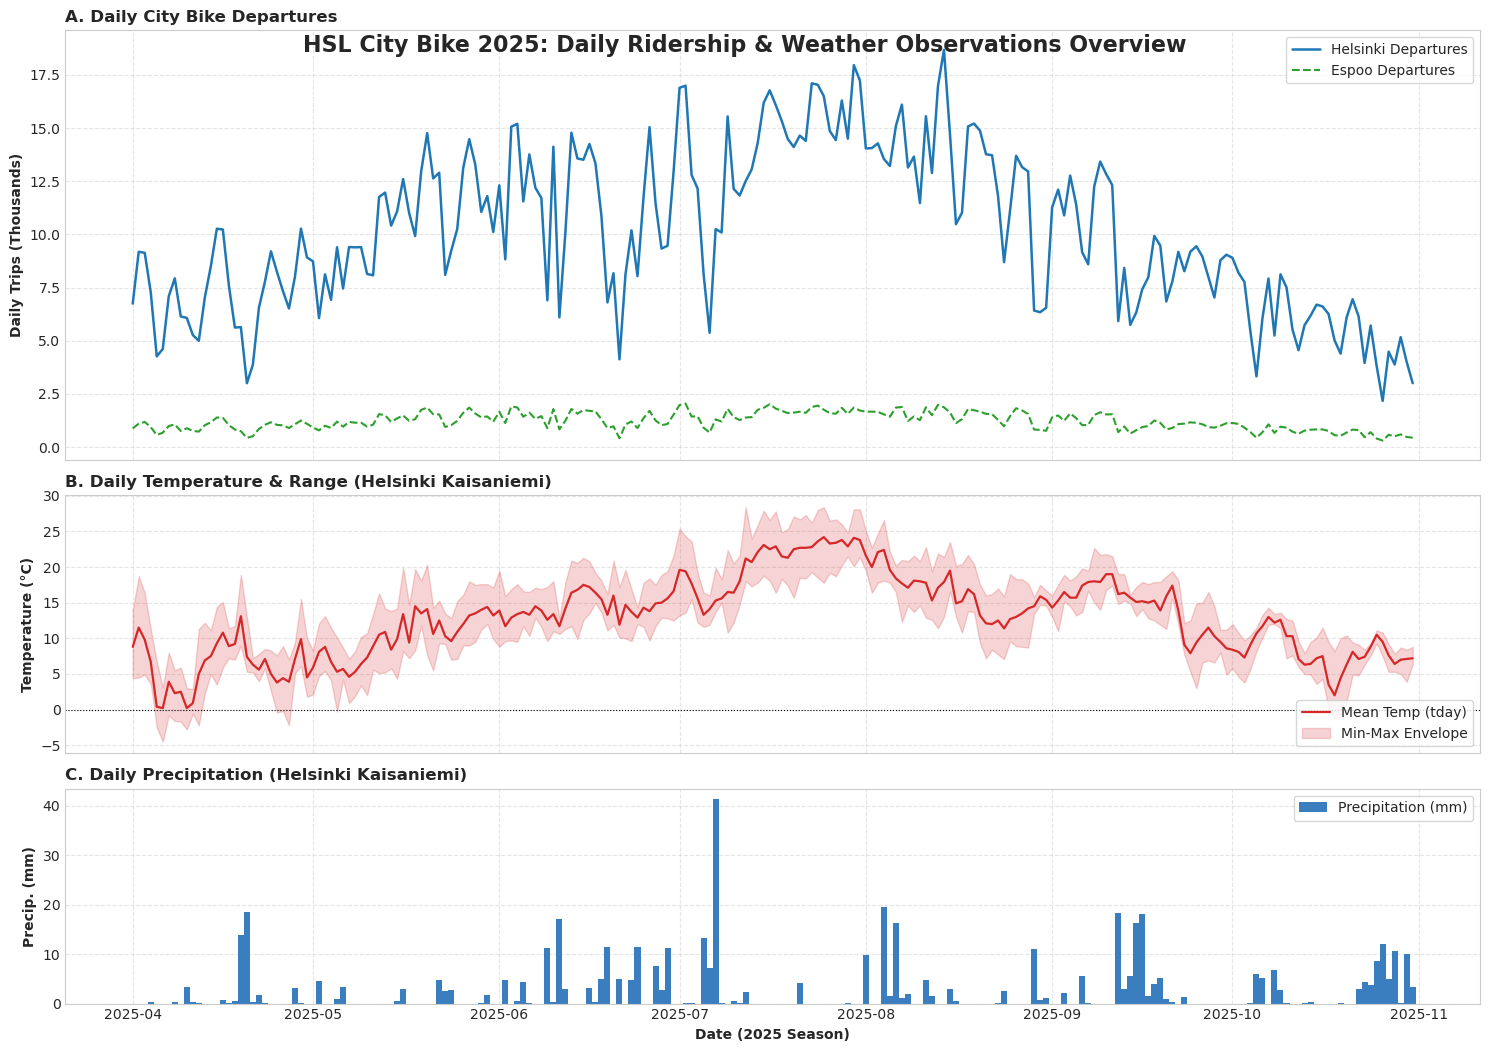

In [6]:
# Filter to mapped cities within active season
df_mapped = df_season[df_season['city'].isin(['Helsinki', 'Espoo'])].sort_values(['date', 'city']).reset_index(drop=True)

# Separate Helsinki and Espoo for plotting
h_df = df_mapped[df_mapped['city'] == 'Helsinki'].copy().set_index('date_dt')
e_df = df_mapped[df_mapped['city'] == 'Espoo'].copy().set_index('date_dt')

fig, axs = plt.subplots(3, 1, figsize=(15, 11), sharex=True, gridspec_kw={'height_ratios': [2, 1.2, 1]})
fig.suptitle('HSL City Bike 2025: Daily Ridership & Weather Observations Overview', fontsize=16, fontweight='bold', y=0.93)

# 1. Daily Departures
axs[0].plot(h_df.index, h_df['departures'] / 1000, label='Helsinki Departures', color='#1f77b4', linewidth=1.8)
axs[0].plot(e_df.index, e_df['departures'] / 1000, label='Espoo Departures', color='#2ca02c', linewidth=1.5, linestyle='--')
axs[0].set_ylabel('Daily Trips (Thousands)', fontweight='bold')
axs[0].set_title('A. Daily City Bike Departures', fontweight='bold', loc='left')
axs[0].legend(loc='upper right', frameon=True)
axs[0].grid(True, linestyle='--', alpha=0.5)

# 2. Daily Temperature Envelope (Helsinki Kaisaniemi)
axs[1].plot(h_df.index, h_df['tday'], color='#d62728', label='Mean Temp (tday)', linewidth=1.6)
axs[1].fill_between(h_df.index, h_df['tmin'], h_df['tmax'], color='#d62728', alpha=0.2, label='Min-Max Envelope')
axs[1].axhline(0, color='black', linestyle=':', linewidth=0.8)
axs[1].set_ylabel('Temperature (°C)', fontweight='bold')
axs[1].set_title('B. Daily Temperature & Range (Helsinki Kaisaniemi)', fontweight='bold', loc='left')
axs[1].legend(loc='lower right', frameon=True)
axs[1].grid(True, linestyle='--', alpha=0.5)

# 3. Daily Precipitation Bars (Helsinki Kaisaniemi)
axs[2].bar(h_df.index, h_df['precip_mm'], color='#3a7ebf', width=1.0, edgecolor='none', label='Precipitation (mm)')
axs[2].set_ylabel('Precip. (mm)', fontweight='bold')
axs[2].set_title('C. Daily Precipitation (Helsinki Kaisaniemi)', fontweight='bold', loc='left')
axs[2].set_xlabel('Date (2025 Season)', fontweight='bold')
axs[2].legend(loc='upper right', frameon=True)
axs[2].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

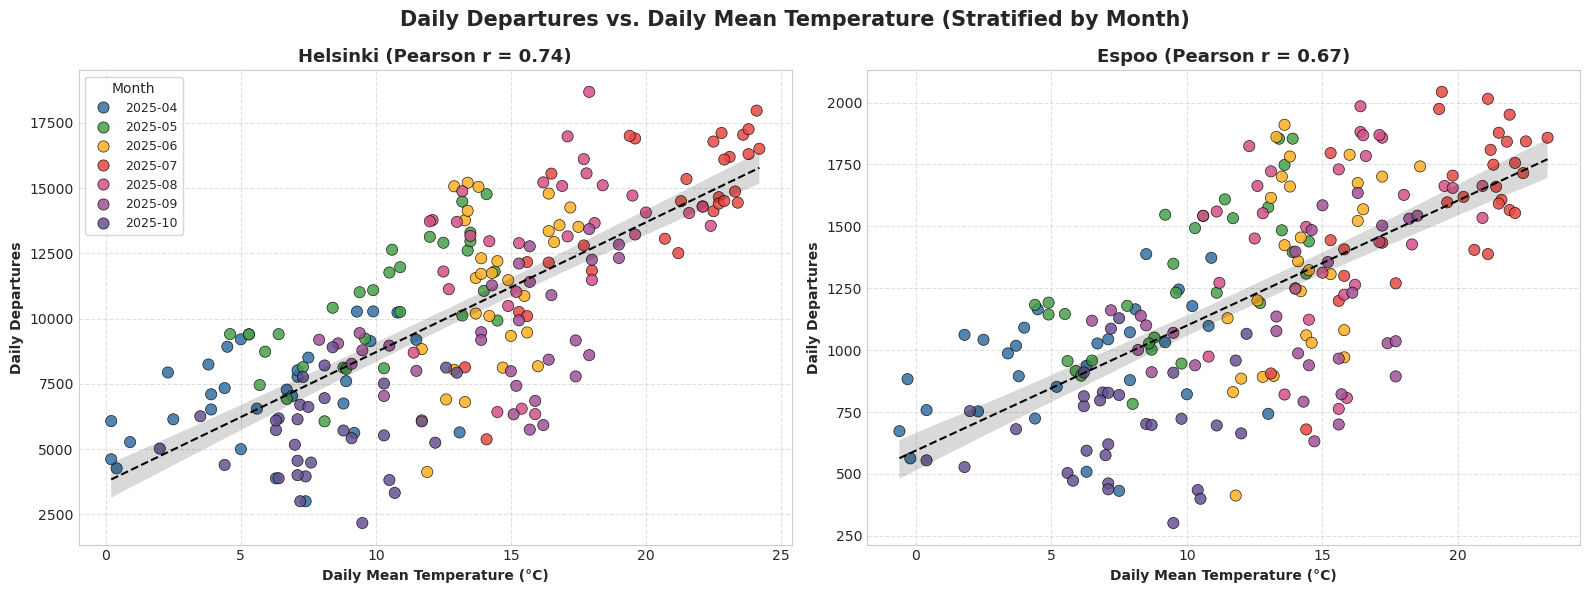

In [7]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6), sharey=False)
fig.suptitle('Daily Departures vs. Daily Mean Temperature (Stratified by Month)', fontsize=15, fontweight='bold')

month_palette = {
    '2025-04': '#3470a3',
    '2025-05': '#45a049',
    '2025-06': '#ffb020',
    '2025-07': '#e64942',
    '2025-08': '#d45087',
    '2025-09': '#a05195',
    '2025-10': '#665191'
}

for i, city in enumerate(['Helsinki', 'Espoo']):
    city_data = df_mapped[df_mapped['city'] == city]
    
    sns.scatterplot(
        data=city_data,
        x='tday',
        y='departures',
        hue='month',
        palette=month_palette,
        s=65,
        alpha=0.85,
        edgecolor='black',
        linewidth=0.5,
        ax=axs[i]
    )
    
    # Overall trend line
    sns.regplot(
        data=city_data,
        x='tday',
        y='departures',
        scatter=False,
        color='black',
        line_kws={'linestyle': '--', 'linewidth': 1.5, 'label': 'Overall Linear Trend'},
        ax=axs[i]
    )
    
    corr = city_data['tday'].corr(city_data['departures'])
    axs[i].set_title(f"{city} (Pearson r = {corr:.2f})", fontweight='bold', fontsize=13)
    axs[i].set_xlabel('Daily Mean Temperature (°C)', fontweight='bold')
    axs[i].set_ylabel('Daily Departures', fontweight='bold')
    axs[i].grid(True, linestyle='--', alpha=0.6)
    
    if i == 0:
        axs[i].legend(title='Month', loc='upper left', frameon=True, fontsize=9)
    else:
        axs[i].legend_.remove()

plt.tight_layout()
plt.show()

C:\Users\luosuo\AppData\Local\Temp\ipykernel_8632\3829318209.py:29: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(
C:\Users\luosuo\AppData\Local\Temp\ipykernel_8632\3829318209.py:51: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  cat_medians = h_data.groupby('rain_category')['departures'].median()


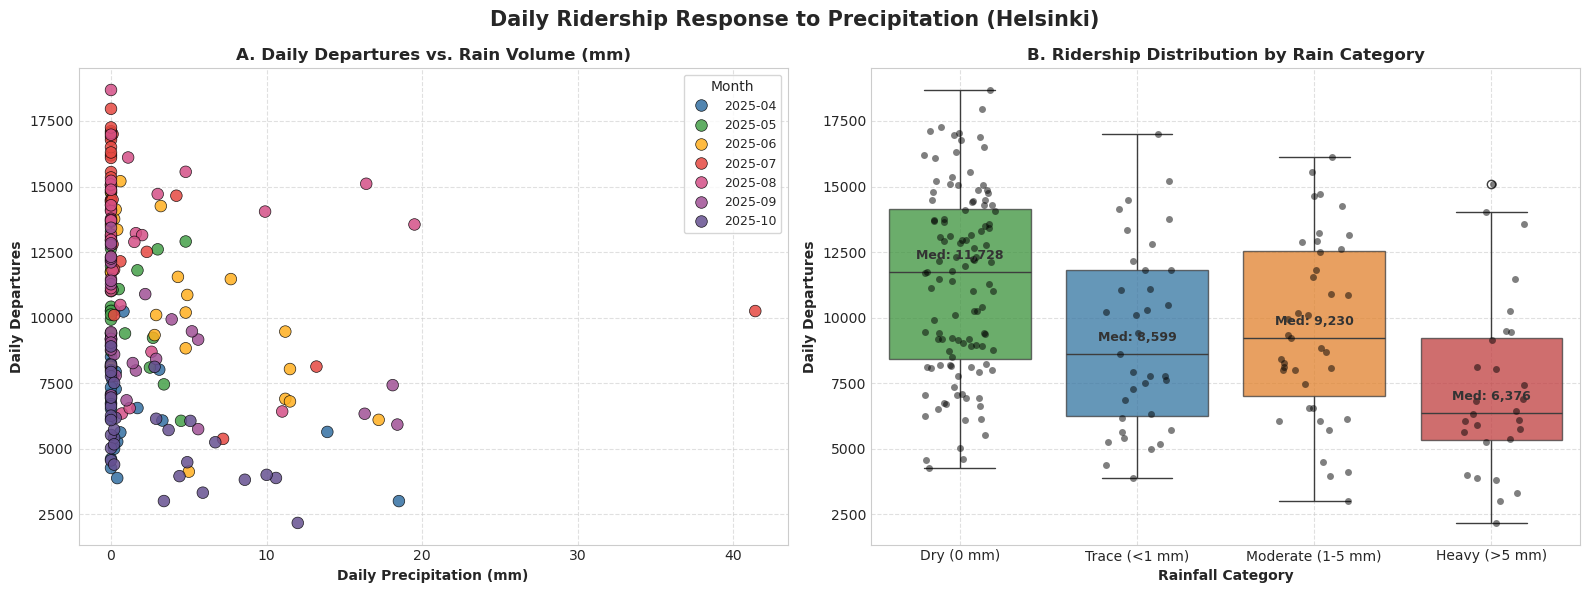

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Daily Ridership Response to Precipitation (Helsinki)', fontsize=15, fontweight='bold')

h_data = df_mapped[df_mapped['city'] == 'Helsinki'].copy()

# Left panel: Scatter of departures vs precipitation (log scale on x for readability)
sns.scatterplot(
    data=h_data,
    x='precip_mm',
    y='departures',
    hue='month',
    palette=month_palette,
    s=70,
    alpha=0.85,
    edgecolor='black',
    linewidth=0.5,
    ax=axs[0]
)
axs[0].set_title('A. Daily Departures vs. Rain Volume (mm)', fontweight='bold')
axs[0].set_xlabel('Daily Precipitation (mm)', fontweight='bold')
axs[0].set_ylabel('Daily Departures', fontweight='bold')
axs[0].grid(True, linestyle='--', alpha=0.6)
axs[0].legend(title='Month', loc='upper right', frameon=True, fontsize=9)

# Right panel: Boxplot across discrete precipitation categories
cat_order = ['Dry (0 mm)', 'Trace (<1 mm)', 'Moderate (1-5 mm)', 'Heavy (>5 mm)']
cat_palette = ['#2ca02c', '#1f77b4', '#ff7f0e', '#d62728']

sns.boxplot(
    data=h_data,
    x='rain_category',
    y='departures',
    order=cat_order,
    palette=cat_palette,
    boxprops={'alpha': 0.75},
    ax=axs[1]
)
sns.stripplot(
    data=h_data,
    x='rain_category',
    y='departures',
    order=cat_order,
    color='black',
    alpha=0.5,
    jitter=0.2,
    size=5,
    ax=axs[1]
)

# Print category medians
cat_medians = h_data.groupby('rain_category')['departures'].median()
for idx, cat in enumerate(cat_order):
    med = cat_medians.get(cat, np.nan)
    if not np.isnan(med):
        axs[1].text(idx, med + 500, f"Med: {med:,.0f}", ha='center', fontweight='bold', fontsize=9, color='#333333')

axs[1].set_title('B. Ridership Distribution by Rain Category', fontweight='bold')
axs[1].set_xlabel('Rainfall Category', fontweight='bold')
axs[1].set_ylabel('Daily Departures', fontweight='bold')
axs[1].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

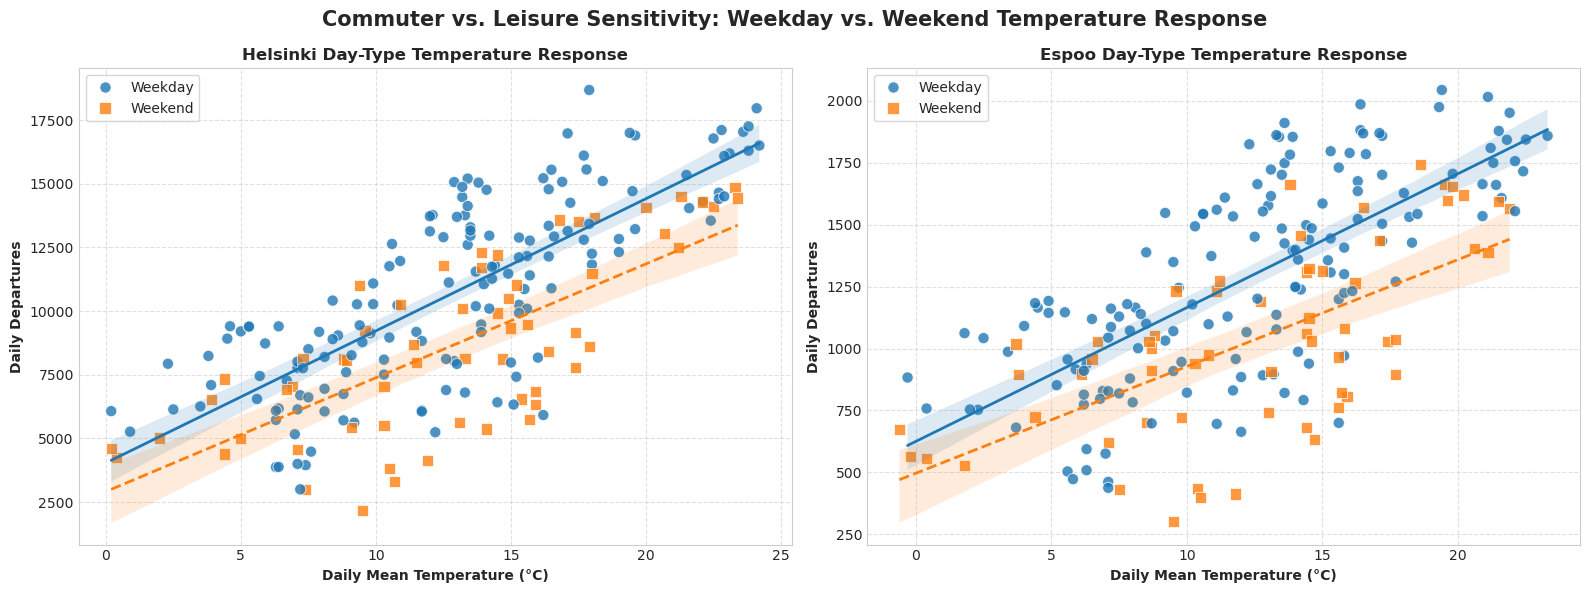

In [9]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('Commuter vs. Leisure Sensitivity: Weekday vs. Weekend Temperature Response', fontsize=15, fontweight='bold')

for i, city in enumerate(['Helsinki', 'Espoo']):
    city_data = df_mapped[df_mapped['city'] == city]
    
    sns.scatterplot(
        data=city_data,
        x='tday',
        y='departures',
        hue='day_type',
        style='day_type',
        palette={'Weekday': '#1f77b4', 'Weekend': '#ff7f0e'},
        markers={'Weekday': 'o', 'Weekend': 's'},
        s=65,
        alpha=0.8,
        ax=axs[i]
    )
    
    # Separate trendlines for Weekdays vs Weekends
    sns.regplot(
        data=city_data[city_data['day_type'] == 'Weekday'],
        x='tday',
        y='departures',
        scatter=False,
        color='#1f77b4',
        line_kws={'linewidth': 2, 'label': 'Weekday Trend'},
        ax=axs[i]
    )
    sns.regplot(
        data=city_data[city_data['day_type'] == 'Weekend'],
        x='tday',
        y='departures',
        scatter=False,
        color='#ff7f0e',
        line_kws={'linewidth': 2, 'linestyle': '--', 'label': 'Weekend Trend'},
        ax=axs[i]
    )
    
    axs[i].set_title(f"{city} Day-Type Temperature Response", fontweight='bold')
    axs[i].set_xlabel('Daily Mean Temperature (°C)', fontweight='bold')
    axs[i].set_ylabel('Daily Departures', fontweight='bold')
    axs[i].grid(True, linestyle='--', alpha=0.6)
    axs[i].legend(loc='upper left', frameon=True)

plt.tight_layout()
plt.show()

## 6. Critical Methodological Discussion

### 6.1 Descriptive Association vs. Causal Attribution
The strong positive correlation between daily mean temperature and ridership ($r \approx 0.74$ in Helsinki, $r \approx 0.67$ in Espoo) and the negative impact of rainfall ($r \approx -0.25$) are **empirical descriptions**, not proof that weather alone causes ridership variations.

In urban transportation systems, weather covaries with major **seasonal confounding mechanisms**:
1. **Daylight and Solar Radiation**: In Helsinki, daily daylight spans nearly 19 hours in late June (Midsummer), but drops to under 9 hours by late October. Commuters and leisure riders are significantly more inclined to cycle in daylight, regardless of temperature.
2. **Institutional & Holiday Cycles**:
   - **July Summer Holidays**: A substantial portion of the Finnish workforce takes annual leave in July. Commuter trips to business hubs (Pasila, Ruoholahti) drop sharply, while leisure trips along coastal paths surge.
   - **School & Academic Calendars**: Universities and schools resume in late August, generating a surge in transit demand that offsets the gradual autumn temperature decline.
3. **Public Transit Substitution**: Inclement weather (rain, cold winds) triggers immediate modal substitution: commuters easily switch to the tram, metro, or bus network rather than enduring wet commutes.

---

### 6.2 Sample Boundaries and Spatial Microclimates
- **Single Season Window**: This analysis spans April to October 2025 ($N = 214$ calendar days). HSL city bikes do not operate during Finnish winter (November to March); therefore, freezing temperature thresholds, snow cycling, and sub-zero demand cannot be evaluated.
- **Macroclimate Representation**: A single station (Kaisaniemi for Helsinki, Tapiola for Espoo) measures regional macroclimate. Coastal stations (e.g., Hernesaari, Jätkäsaari) experience high marine wind chills, while localized afternoon summer showers may soak one neighborhood while leaving another dry.

---

### 6.3 Avoiding Pseudo-Replication & The Ecological Fallacy
A frequent methodological pitfall in spatial data science is **pseudo-replication**:
- If an analyst takes `station_month.csv` ($N = 3,197$ rows) and runs a statistical regression between station-level departures and monthly temperature, they treat each station-month row as an independent sample.
- In reality, all 347 Helsinki stations in July share the **exact same** monthly weather value ($20.5^\circ\text{C}$). Treating them as 347 independent data points inflates the statistical degrees of freedom by a factor of 25, creating artificially narrow confidence intervals and false statistical significance.
- In this notebook, we solved this issue by **aggregating trip demand to the exact spatial-temporal granularity of the weather observation**: daily municipality totals ($N = 214 \text{ days} \times 2 \text{ cities} = 428$ observations). Each row represents an independent calendar day's environmental condition.

In [10]:
# Compute correlation matrix for Helsinki and Espoo
corr_data = []

for city in ['Helsinki', 'Espoo']:
    sub = df_mapped[df_mapped['city'] == city]
    corr_data.append({
        'City': city,
        'Observations (Days)': len(sub),
        'Corr(Departures, tday)': round(sub['departures'].corr(sub['tday']), 3),
        'Corr(Departures, tmin)': round(sub['departures'].corr(sub['tmin']), 3),
        'Corr(Departures, tmax)': round(sub['departures'].corr(sub['tmax']), 3),
        'Corr(Departures, precip_mm)': round(sub['departures'].corr(sub['precip_mm']), 3),
        'Mean Daily Departures': int(sub['departures'].mean()),
        'Max Daily Departures': int(sub['departures'].max()),
        'Min Daily Departures': int(sub['departures'].min()),
    })

corr_df = pd.DataFrame(corr_data)
print("=" * 85)
print("SUMMARY CORRELATION AND ACTIVITY METRICS TABLE (2025 CYCLING SEASON)")
print("=" * 85)
display(corr_df)

SUMMARY CORRELATION AND ACTIVITY METRICS TABLE (2025 CYCLING SEASON)


,City,Observations (Days),"Corr(Departures, tday)","Corr(Departures, tmin)","Corr(Departures, tmax)","Corr(Departures, precip_mm)",Mean Daily Departures,Max Daily Departures,Min Daily Departures
0,Helsinki,214,0.737,0.622,0.788,-0.251,10139,18682,2168
1,Espoo,214,0.665,0.515,0.751,-0.289,1215,2043,302
